# Chapter 3, Gaussian filters: run first, read second

This notebook is the hands-on companion of chapter 3 of *Probabilistic Robotics* (Thrun, Burgard, Fox, 2005), book pages 39 to 84. The method is to run the filters before reading the text, so that every section you read answers a question the code produced.

**How to use it.** Run the cells top to bottom (about 10 minutes). Then change one parameter at a time in Part 2 and watch what breaks. Only then open the book sections listed in Part 4.

**What it reuses.** The Extended Kalman Filter simulation of [PythonRobotics](https://github.com/AtsushiSakai/PythonRobotics) (`Localization/extended_kalman_filter`) and its plotting helper. The notebook imports their functions and writes its own loop, so the filter equations stay visible and can be mapped line by line to Table 3.3 of the book. Run `../setup.sh` once to clone the external repositories into `_external/`.

**Companion material.** The notebook book [Kalman and Bayesian Filters in Python](https://github.com/rlabbe/Kalman-and-Bayesian-Filters-in-Python) by Roger Labbe covers the same chapter with more intuition: open `04-One-Dimensional-Kalman-Filters.ipynb` and `06-Multivariate-Kalman-Filters.ipynb` from `_external/` in this same Jupyter session. The ROS 2 series of Carlos Argueta has an article and a demo video per filter ([Kalman filter article](https://medium.com/@kidargueta/recursive-state-estimation-with-kalman-filters-and-ros-2-b869d3775357), [EKF article](https://medium.com/@kidargueta/sensor-fusion-with-the-extended-kalman-filter-in-ros-2-d33dbab1829d), [KF demo video](https://youtu.be/TPbO3kBygb4)).

In [1]:
import importlib.util
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

HERE = Path.cwd() if (Path.cwd() / "_external").exists() else Path.cwd().parent
PR = HERE / "_external" / "PythonRobotics"
assert PR.exists(), "run ../setup.sh first to clone PythonRobotics into _external/"
sys.path.append(str(PR))  # for PythonRobotics' own `utils` package

def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

ekf = load_module("pr_ekf", PR / "Localization" / "extended_kalman_filter" / "extended_kalman_filter.py")
ekf.show_animation = False  # their main() animates, we plot inline instead
from utils.plot import plot_ellipse

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(seed=3)
print("PythonRobotics EKF loaded. DT =", ekf.DT, "s, SIM_TIME =", ekf.SIM_TIME, "s")
print("Their process noise Q (diagonal):", np.round(np.diag(ekf.Q), 4))
print("Their measurement noise R (diagonal):", np.diag(ekf.R))
print("The noise they actually add to the GPS (matrix GPS_NOISE):", np.diag(ekf.GPS_NOISE))

PythonRobotics EKF loaded. DT = 0.1 s, SIM_TIME = 50.0 s
Their process noise Q (diagonal): [1.e-02 1.e-02 3.e-04 1.e+00]
Their measurement noise R (diagonal): [1. 1.]
The noise they actually add to the GPS (matrix GPS_NOISE): [0.25 0.25]


## Part 1. Run their EKF with your own loop

The robot drives a circle (constant speed 1 m/s, yaw rate 0.1 rad/s). The state is $[x, y, \theta, v]$. The control input is noisy (dead reckoning drifts) and a GPS-like sensor measures $(x, y)$ with noise. The filter below is their `ekf_estimation` written out with the book's line numbers from **Table 3.3** (EKF algorithm, book page 59), plus two values the book never plots: the innovation $y = z - h(\bar\mu)$ and its covariance $S$.

In [2]:
def ekf_step(x_est, P_est, z, u, R):
    """One EKF iteration, Table 3.3 of the book, reusing the PythonRobotics models."""
    # Table 3.3, line 2: predicted mean through the nonlinear motion model g(u, mu)
    x_pred = ekf.motion_model(x_est, u)
    # line 3: predicted covariance with the Jacobian G of the motion model
    G = ekf.jacob_f(x_est, u)
    P_pred = G @ P_est @ G.T + ekf.Q
    # line 4: Kalman gain K with the Jacobian H of the measurement model
    H = ekf.jacob_h()
    S = H @ P_pred @ H.T + R  # innovation covariance, the book keeps it inside line 4
    K = P_pred @ H.T @ np.linalg.inv(S)
    # line 5: corrected mean, with the innovation y = z - h(mu_bar)
    y = z - ekf.observation_model(x_pred)
    x_est = x_pred + K @ y
    # line 6: corrected covariance. Note that z never appears in this line.
    P_est = (np.eye(len(x_est)) - K @ H) @ P_pred
    return x_est, P_est, y, S


def simulate(gps_std_fn, R_fn, seed=3, sim_time=None):
    """Drive the circle, measure with GPS noise std = gps_std_fn(range), filter with R = R_fn(range_estimate).

    Returns a dict of histories: true states, dead reckoning, measurements, estimates, innovations, S, P.
    """
    rng = np.random.default_rng(seed)
    sim_time = sim_time or ekf.SIM_TIME
    x_true = np.zeros((4, 1)); x_dr = np.zeros((4, 1)); x_est = np.zeros((4, 1)); P = np.eye(4)
    h = {k: [] for k in ("t", "true", "dr", "z", "est", "y", "S", "P", "R")}
    t = 0.0
    while t <= sim_time:
        t += ekf.DT
        u = ekf.calc_input()
        x_true = ekf.motion_model(x_true, u)
        range_true = math.hypot(x_true[0, 0], x_true[1, 0])
        z = ekf.observation_model(x_true) + gps_std_fn(range_true) * rng.standard_normal((2, 1))
        u_noisy = u + ekf.INPUT_NOISE @ rng.standard_normal((2, 1))
        x_dr = ekf.motion_model(x_dr, u_noisy)
        range_est = math.hypot(x_est[0, 0], x_est[1, 0])
        R = R_fn(range_est)
        x_est, P, y, S = ekf_step(x_est, P, z, u_noisy, R)
        for k, v in (("t", t), ("true", x_true), ("dr", x_dr), ("z", z), ("est", x_est), ("y", y), ("S", S), ("P", P), ("R", R)):
            h[k].append(np.array(v, dtype=float))
    return {k: np.array(v) for k, v in h.items()}


def position_rmse(h):
    err = h["est"][:, :2, 0] - h["true"][:, :2, 0]
    return float(np.sqrt(np.mean(np.sum(err**2, axis=1))))


# Their setup: the filter believes R = diag(1, 1), the simulator adds GPS noise with matrix GPS_NOISE = diag(0.25, 0.25)
their_gps_std = float(ekf.GPS_NOISE[0, 0])  # 0.25 m, because GPS_NOISE @ randn scales by the matrix, not by its square root
run1 = simulate(gps_std_fn=lambda r: their_gps_std, R_fn=lambda r: ekf.R)
print(f"GPS noise std actually simulated: {their_gps_std:.2f} m. Filter R std: {math.sqrt(ekf.R[0, 0]):.2f} m.")
print(f"Position RMSE, EKF: {position_rmse(run1):.3f} m")
err_dr = run1["dr"][:, :2, 0] - run1["true"][:, :2, 0]
print(f"Position RMSE, dead reckoning only: {np.sqrt(np.mean(np.sum(err_dr**2, axis=1))):.3f} m")
nis1 = np.einsum("ti,tij,tj->t", run1["y"][:, :, 0], np.linalg.inv(run1["S"]), run1["y"][:, :, 0])
print(f"Steps with NIS below the chi2 95 % line: {np.mean(nis1 < stats.chi2.ppf(0.95, df=2)) * 100:.0f} % (a consistent filter gives about 95 %)")

GPS noise std actually simulated: 0.25 m. Filter R std: 1.00 m.
Position RMSE, EKF: 0.182 m
Position RMSE, dead reckoning only: 2.638 m
Steps with NIS below the chi2 95 % line: 100 % (a consistent filter gives about 95 %)


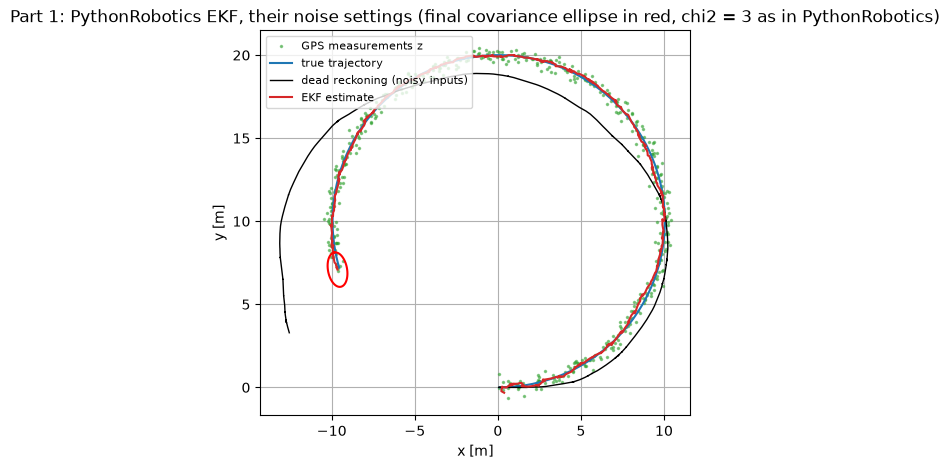

In [3]:
def plot_trajectories(h, title):
    fig, ax = plt.subplots()
    ax.plot(h["z"][:, 0, 0], h["z"][:, 1, 0], ".", color="tab:green", ms=3, alpha=0.5, label="GPS measurements z")
    ax.plot(h["true"][:, 0, 0], h["true"][:, 1, 0], "-", color="tab:blue", label="true trajectory")
    ax.plot(h["dr"][:, 0, 0], h["dr"][:, 1, 0], "-", color="k", lw=1, label="dead reckoning (noisy inputs)")
    ax.plot(h["est"][:, 0, 0], h["est"][:, 1, 0], "-", color="tab:red", label="EKF estimate")
    # final 1-sigma ellipse of the position block of P, drawn with PythonRobotics' plot_ellipse (eigh keeps the eigenvalues real)
    Pxy = h["P"][-1][:2, :2]
    eig_val, eig_vec = np.linalg.eigh(0.5 * (Pxy + Pxy.T))
    plot_ellipse(h["est"][-1, 0, 0], h["est"][-1, 1, 0], math.sqrt(3.0 * eig_val[1]), math.sqrt(3.0 * eig_val[0]), math.atan2(eig_vec[1, 1], eig_vec[0, 1]), ax=ax)
    ax.set_aspect("equal"); ax.grid(True); ax.legend(loc="upper left", fontsize=8); ax.set_title(title)
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    return fig

plot_trajectories(run1, "Part 1: PythonRobotics EKF, their noise settings (final covariance ellipse in red, chi2 = 3 as in PythonRobotics)");

### The filter's own view: the innovation

Line 6 of Table 3.3 never uses the measurement $z$. The covariance $\Sigma_t$ shrinks on every update whether the measurement was good or not. The only place a wrong measurement can show itself is the innovation $y = z - h(\bar\mu)$, which should stay inside $\pm 2\sqrt{S}$ about 95 % of the time if the filter is consistent. The normalized innovation squared $y^\top S^{-1} y$ (NIS) should follow a $\chi^2$ distribution with 2 degrees of freedom. The book introduces the test on the innovation only in chapter 7 (Mahalanobis gate, Table 7.2), but you can already see it here.

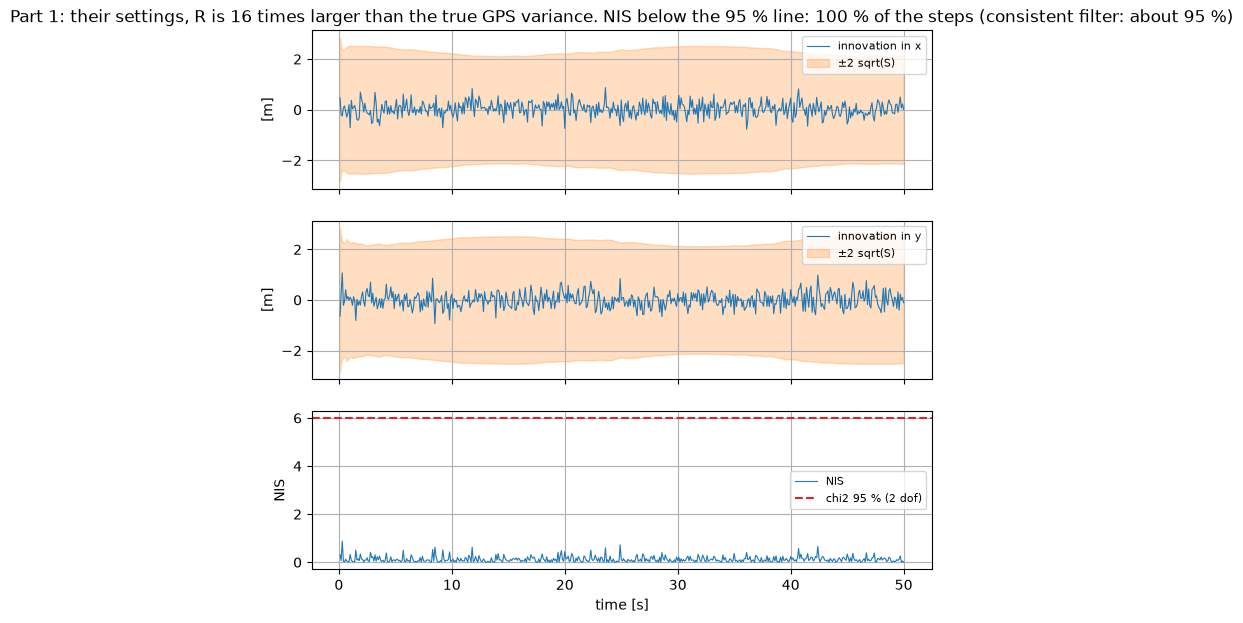

In [4]:
def nis(h):
    y = h["y"][:, :, 0]; S = h["S"]
    return np.einsum("ti,tij,tj->t", y, np.linalg.inv(S), y)

def plot_innovation(h, title):
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 7))
    t = h["t"]
    for i, name in enumerate(("x", "y")):
        sig = np.sqrt(h["S"][:, i, i])
        axes[i].plot(t, h["y"][:, i, 0], lw=0.8, label=f"innovation in {name}")
        axes[i].fill_between(t, -2 * sig, 2 * sig, color="tab:orange", alpha=0.25, label="±2 sqrt(S)")
        axes[i].legend(loc="upper right", fontsize=8); axes[i].grid(True); axes[i].set_ylabel("[m]")
    v = nis(h)
    axes[2].plot(t, v, lw=0.8, label="NIS")
    axes[2].axhline(stats.chi2.ppf(0.95, df=2), color="tab:red", ls="--", label="chi2 95 % (2 dof)")
    axes[2].set_ylabel("NIS"); axes[2].set_xlabel("time [s]"); axes[2].grid(True); axes[2].legend(fontsize=8)
    inside = np.mean(v < stats.chi2.ppf(0.95, df=2)) * 100
    axes[0].set_title(f"{title}. NIS below the 95 % line: {inside:.0f} % of the steps (consistent filter: about 95 %)")
    return fig

plot_innovation(run1, "Part 1: their settings, R is 16 times larger than the true GPS variance");

**Something to notice before reading.** PythonRobotics adds GPS noise as `GPS_NOISE @ randn`, where `GPS_NOISE = diag(0.5, 0.5) ** 2`. A matrix product scales the noise by the matrix entries (0.25), not by their square roots (0.5), so the simulated GPS noise standard deviation is 0.25 m while the filter is told `R = diag(1, 1)`, a standard deviation of 1 m. The filter is 4 times too pessimistic about its sensor (16 times in variance). The NIS plot shows it: the printed percentage of steps below the 95 % line is far above 95, and the innovation never comes near the $\pm 2\sqrt{S}$ band. Book section 3.2.4 (the Kalman filter in practice) and section 3.3.4 (practical considerations of the EKF) talk about this choice of noise parameters. Keep this in mind for the reading group: it is a common bug in real systems, and the filter does not complain.

## Part 2. Make it yours: a sensor whose noise grows with range

Many real sensors get worse with distance (a camera that measures the position of a small drone, a range sensor). Here the GPS noise standard deviation grows linearly with the distance of the robot from the origin, $\sigma(r) = 0.3 + 0.08\, r$. Two filters see the same measurements:

- **Filter A** keeps a constant $R$ tuned for the near field ($\sigma = 0.5$ m).
- **Filter B** uses the true noise model, evaluated at the estimated range, $R = \sigma(\hat r)^2 I$.

The question to answer with the plots: does the wrong $R$ hurt the estimate, the consistency, or both?

In [5]:
sigma_of_range = lambda r: 0.3 + 0.08 * r
runA = simulate(gps_std_fn=sigma_of_range, R_fn=lambda r: np.diag([0.5, 0.5]) ** 2, sim_time=120.0)
runB = simulate(gps_std_fn=sigma_of_range, R_fn=lambda r: np.eye(2) * sigma_of_range(r) ** 2, sim_time=120.0)
print(f"Position RMSE. Filter A (constant R): {position_rmse(runA):.3f} m. Filter B (range-dependent R): {position_rmse(runB):.3f} m.")
for name, h in (("A", runA), ("B", runB)):
    inside = np.mean(nis(h) < stats.chi2.ppf(0.95, df=2)) * 100
    print(f"Filter {name}: NIS below the 95 % line in {inside:.0f} % of the steps")

Position RMSE. Filter A (constant R): 0.959 m. Filter B (range-dependent R): 0.715 m.
Filter A: NIS below the 95 % line in 45 % of the steps
Filter B: NIS below the 95 % line in 96 % of the steps


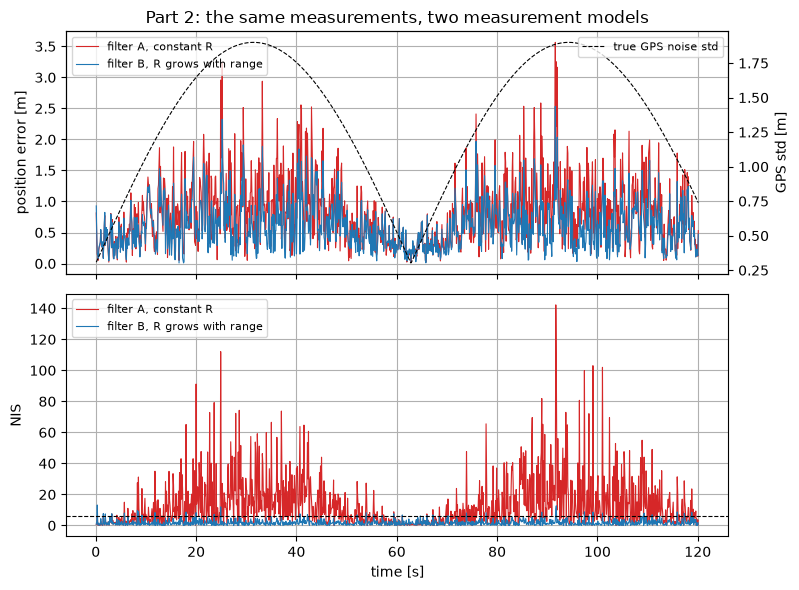

In [6]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 6))
for name, h, c in (("A, constant R", runA, "tab:red"), ("B, R grows with range", runB, "tab:blue")):
    err = np.linalg.norm(h["est"][:, :2, 0] - h["true"][:, :2, 0], axis=1)
    axes[0].plot(h["t"], err, lw=0.8, color=c, label=f"filter {name}")
    axes[1].plot(h["t"], nis(h), lw=0.8, color=c, label=f"filter {name}")
r_true = np.linalg.norm(runA["true"][:, :2, 0], axis=1)
ax2 = axes[0].twinx(); ax2.plot(runA["t"], sigma_of_range(r_true), "k--", lw=0.8, label="true GPS noise std"); ax2.set_ylabel("GPS std [m]"); ax2.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("position error [m]"); axes[0].grid(True); axes[0].legend(loc="upper left", fontsize=8)
axes[0].set_title("Part 2: the same measurements, two measurement models")
axes[1].axhline(stats.chi2.ppf(0.95, df=2), color="k", ls="--", lw=0.8); axes[1].set_ylabel("NIS"); axes[1].set_xlabel("time [s]"); axes[1].grid(True); axes[1].legend(fontsize=8)
plt.tight_layout();

**Things to try now** (one at a time, then re-run the two cells above):

1. Multiply `ekf.Q` by 10 or by 0.1 before running (`ekf.Q = ekf.Q * 10`). Which filter suffers more, and does the NIS tell you?
2. Make the robot drive away instead of in a circle: set `ekf.calc_input = lambda: np.array([[1.0], [0.0]])` and run for 120 s. The range grows without bound, and so does the gap between filters A and B.
3. Drop the GPS for 10 seconds (skip the update when `40 < t < 50`) and watch the covariance ellipse grow, then collapse at the first measurement after the gap. Is the first innovation after the gap inside $\pm 2\sqrt{S}$?
4. Replace `ekf_step` with the Unscented Kalman Filter of `Localization/unscented_kalman_filter` (functions `setup_ukf` and `ukf_estimation`). Does the UKF change anything for this almost-linear problem? Book section 3.4.

## Part 3. Questions for the reading group

1. Line 6 of Table 3.3 updates $\Sigma_t$ without looking at $z_t$. Where in the book's algorithms does a measurement first get the chance to be rejected? (Chapter 7, Table 7.2, line 21.)
2. PythonRobotics tells the filter a measurement noise 4 times larger than what it simulates, and the estimate still looks fine in Part 1. When does an over-pessimistic $R$ actually hurt? (Hint: Part 2, filter A, far from the origin, and anything that depends on $\Sigma_t$ such as a gate or a planner.)
3. The book presents the EKF as a fix for nonlinear models (section 3.3). In Part 2 the model is almost linear and the problem is the noise model. Which of the two matters more in practice, and does chapter 3 give any tool for the second one?

## Part 4. Now read

Each section is tied to a cell above, so you read with a question in mind.

| Read | Pages | The question it answers |
| --- | --- | --- |
| 3.2.1 and 3.2.2, the linear Kalman filter and Table 3.1 | 40 to 43 | What each of the 6 lines in `ekf_step` does in the linear case |
| 3.2.4, the KF in practice, and the 1D illustration (Fig. 3.2) | 43 to 47 | Why the covariance shrinks on every update, independent of $z$ |
| 3.3.1 to 3.3.3, why linearize, Table 3.3, the Jacobians | 48 to 59 | Where `jacob_f` and `jacob_h` come from |
| 3.3.4, practical considerations | 59 to 63 | The choice of $Q$ and $R$, and what goes wrong in Part 2 |
| 3.4, the UKF | 65 to 70 | Exercise 4 above |
| 3.5, the information filter | 71 to 76 | Skim, it comes back for multi-robot fusion |

Then open `_external/Kalman-and-Bayesian-Filters-in-Python/04-One-Dimensional-Kalman-Filters.ipynb` for the intuition the book skips, and `06-Multivariate-Kalman-Filters.ipynb` for the same filter written with FilterPy.